# Projeto de Otimização de Margem de Lucro: Seleção de Regiões para Poços de Petróleo

---

# 1. Apresentação e Prólogo: Contexto do Negócio

## Contexto e Regras de Negócio
A empresa OilyGiant busca identificar a melhor região para o desenvolvimento de 200 novos poços de petróleo. O orçamento total disponível é de **$100.000.000** (100 milhões de dólares), e dispomos de dados mapeados em três regiões distintas (Região 0, Região 1 e Região 2).

### Premissas Financeiras:
* **Investimento total:** $100.000.000 (para 200 poços).
* **Custo de desenvolvimento por poço:** $500.000 ($100M / 200).
* **Receita por unidade de volume:** $4.500 por unidade de volume (1 unidade = 1.000 barris).
* **Critério de Seleção de Risco:** A região escolhida deve apresentar um risco de prejuízo financeiro **inferior a 2,5%**.

## Cálculo do Ponto de Equilíbrio (Break-Even Point)
Para que o investimento de $100M seja totalmente coberto e não gere prejuízo, o volume total exigido nos 200 poços e o volume médio por poço são calculados da seguinte forma:

$$\text{Volume Total Necessário} = \frac{\$100.000.000}{\$4.500} = 22.222,22 \text{ unidades}$$

$$\text{Volume Médio Mínimo por Poço} = \frac{22.222,22}{200} = 111,11 \text{ unidades (mil barris)}$$

### Análise Crítica do Break-Even vs. Médias Populacionais:
Ao analisar a média populacional de produção em cada região no dataset completo:
* **Região 0:** Média de ~92,50 mil barris por poço.
* **Região 1:** Média de ~68,72 mil barris por poço.
* **Região 2:** Média de ~95,00 mil barris por poço.

**Conclusão de Negócio:** Nenhuma das três regiões atinge a média populacional necessária de 111,11 mil barris por poço. A perfuração aleatória de poços em qualquer uma das regiões resultará em prejuízo garantido. Por isso, é indispensável construir um modelo preditivo de Regressão Linear capaz de filtrar e selecionar estrategicamente os 200 poços com maior potencial produtivo.

## 2. Sumário / Índice do Projeto

1. [Importação de Bibliotecas e Configuração do Ambiente](#31-importação-de-bibliotecas)
2. [Carregamento e Inspeção Inicial dos Dados](#32-carregamento-e-inspeção-dos-dados)
3. [Tratamento de Dados, Divisão e Padronização (StandardScaler)](#33-tratamento-divisão-e-padronização-dos-dados)
4. [Treinamento e Validação dos Modelos de Regressão Linear](#34-treinamento-e-validação-dos-modelos)
5. [Cálculo do Ponto de Equilíbrio (Break-Even Analysis)](#35-cálculo-do-ponto-de-equilíbrio)
6. [Cálculo do Lucro Real com Base nos Melhores Poços Selecionados](#36-cálculo-do-lucro-dos-melhores-poços)
7. [Análise de Riscos e Intervalo de Confiança (Bootstrap)](#37-análise-de-riscos-com-bootstrap)
8. [Conclusão e Recomendação Executiva](#38-conclusão-e-recomendação-executiva)

## 3. Código e Explicações Passo a Passo

### 3.1 Importação de Bibliotecas
Importamos as bibliotecas necessárias para manipulação de dados, padronização de atributos (`StandardScaler`), treinamento de modelos de Regressão Linear, avaliação de métricas e visualizações estatísticas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Configuração de estilo para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Configuração de exibição do Pandas
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### 3.2 Carregamento e Inspeção dos Dados
Lemos os arquivos das três regiões testando as URLs do S3, com fallbacks para os caminhos locais e do servidor, inspecionando suas estruturas e integridade.

In [2]:
# Mapeamento com URLs do S3, caminhos locais e diretório do servidor
paths = {
    'Região 0': [
        'https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_0.csv',
        'geo_data_0.csv',
        '/datasets/geo_data_0.csv'
    ],
    'Região 1': [
        'https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_1.csv',
        'geo_data_1.csv',
        '/datasets/geo_data_1.csv'
    ],
    'Região 2': [
        'https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_2.csv',
        'geo_data_2.csv',
        '/datasets/geo_data_2.csv'
    ]
}

dataframes = {}

for name, possible_paths in paths.items():
    df = None
    for path in possible_paths:
        try:
            df = pd.read_csv(path)
            print(f"Carregado com sucesso a partir de: {path}")
            break
        except Exception:
            continue
            
    if df is not None:
        dataframes[name] = df
        print(f"=== {name} ===")
        print(f"Formato (Linhas, Colunas): {df.shape}")
        print(f"Valores Ausentes:\n{df.isnull().sum()}")
        print(f"Duplicadas exatas: {df.duplicated().sum()}")
        print(df.head(3))
        print("-" * 50)
    else:
        print(f"Erro: Não foi possível carregar os dados para {name}.")

Carregado com sucesso a partir de: https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_0.csv
=== Região 0 ===
Formato (Linhas, Colunas): (100000, 5)
Valores Ausentes:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64
Duplicadas exatas: 0
      id    f0     f1    f2  product
0  txEyH 0.706 -0.498 1.221  105.280
1  2acmU 1.335 -0.340 4.365   73.038
2  409Wp 1.023  0.152 1.420   85.266
--------------------------------------------------
Carregado com sucesso a partir de: https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_1.csv
=== Região 1 ===
Formato (Linhas, Colunas): (100000, 5)
Valores Ausentes:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64
Duplicadas exatas: 0
      id      f0     f1     f2  product
0  kBEdx -15.001 -8.276 -0.006    3.179
1  62mP7  14.272 -3.475  0.999   26.953
2  vyE1P   6.263 -5.948  5.001  134.766
--------------------------------------------------
Carregado com sucess

### 3.3 Tratamento de Dados, Divisão e Padronização (StandardScaler)
1. Removemos a coluna `id`, pois é apenas um identificador sem poder preditivo.
2. Separamos as características ($X$) da variável alvo ($y = \text{product}$).
3. Dividimos os dados na proporção **75% Treino / 25% Validação** (`random_state=42`).
4. Aplicamos o **`StandardScaler`**: ajustamos o escalonador no conjunto de treino (`fit_transform`) e o aplicamos no conjunto de validação (`transform`), evitando *data leakage*.

In [3]:
prepared_data = {}

for name, df in dataframes.items():
    # 1. Separação das features (X) e do alvo/target (y)
    X = df.drop(columns=['id', 'product'])
    y = df['product']
    
    # 2. Divisão em Treino (75%) e Validação (25%)
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.25, random_state=12345
    )
    
    # Reset de índices essencial para alinhar as posições no Bootstrap e na filtragem
    y_train = y_train.reset_index(drop=True)
    y_val = y_val.reset_index(drop=True)
    
    # 3. Padronização das variáveis numéricas
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    prepared_data[name] = {
        'X_train': X_train_scaled,
        'X_val': X_val_scaled,
        'y_train': y_train,
        'y_val': y_val
    }

print("Divisão de dados, reset de índices e padronização concluídos com sucesso sem Data Leakage.")

Divisão de dados, reset de índices e padronização concluídos com sucesso sem Data Leakage.


### 3.4 Treinamento e Validação dos Modelos de Regressão Linear
Para cada região:
1. Treinamos a **Regressão Linear** utilizando as características padronizadas do conjunto de treino.
2. Geramos predições para o conjunto de validação.
3. Calculamos o volume médio previsto, o volume médio real e a **Raiz do Erro Quadrático Médio (RMSE)**.

In [4]:
for name, data in prepared_data.items():
    model = LinearRegression()
    model.fit(data['X_train'], data['y_train'])
    
    # Converte o array de predições para Pandas Series garantindo reset_index
    predictions = pd.Series(model.predict(data['X_val'])).reset_index(drop=True)
    
    prepared_data[name]['predictions'] = predictions
    prepared_data[name]['model'] = model
    
    rmse = np.sqrt(mean_squared_error(data['y_val'], predictions))
    mean_pred = predictions.mean()
    
    print(f"=== Resultados do Modelo - {name} ===")
    print(f"Volume Médio Previsto: {mean_pred:.2f} mil barris")
    print(f"RMSE do Modelo: {rmse:.2f}\n")

=== Resultados do Modelo - Região 0 ===
Volume Médio Previsto: 92.59 mil barris
RMSE do Modelo: 37.58

=== Resultados do Modelo - Região 1 ===
Volume Médio Previsto: 68.73 mil barris
RMSE do Modelo: 0.89

=== Resultados do Modelo - Região 2 ===
Volume Médio Previsto: 94.97 mil barris
RMSE do Modelo: 40.03



### Análise Crítica dos Modelos por Região:
* **Região 0:** Obteve volume médio previsto de **~92,59 mil barris** com RMSE de **37,57**. O erro do modelo é elevado (cerca de 40% da média), o que gera imprecisão ao ranquear os melhores poços.
* **Região 1:** Obteve volume médio previsto de **~68,72 mil barris** com RMSE impressionante de apenas **0,89**. Essa altíssima acurácia se deve à forte correlação linear quase perfeita entre o atributo `f2` e a variável alvo `product`. O modelo nesta região praticamente não erra.
* **Região 2:** Obteve volume médio previsto de **~94,96 mil barris** com RMSE de **40,03**. Apresenta a maior variação e incerteza preditiva entre todas as regiões.

### 3.5 Cálculo do Ponto de Equilíbrio (Break-Even Analysis)
Determinamos o volume mínimo de petróleo por poço necessário para cobrir o custo de desenvolvimento sem prejuízo.

In [5]:
# Constantes Financeiras
BUDGET = 100_000_000          # Orçamento total ($100 milhões)
N_SELECTED_WELLS = 200        # Poços a desenvolver
REVENUE_PER_UNIT = 4_500      # Receita por 1.000 barris ($4.500)

# Custo por poço individual
cost_per_well = BUDGET / N_SELECTED_WELLS

# Volume necessário para Break-Even (por poço)
break_even_volume = cost_per_well / REVENUE_PER_UNIT

print(f"Custo de desenvolvimento por poço: ${cost_per_well:,.2f}")
print(f"Volume necessário para Break-Even (por poço): {break_even_volume:.2f} mil barris")
print("-" * 65)

for name, data in prepared_data.items():
    # Calcula a média do volume real (target) para cada região
    mean_true = data['y_val'].mean()
    diff = mean_true - break_even_volume
    print(f"{name}: Média Real = {mean_true:.2f} mil barris | Déficit vs Break-Even: {diff:.2f} mil barris")

Custo de desenvolvimento por poço: $500,000.00
Volume necessário para Break-Even (por poço): 111.11 mil barris
-----------------------------------------------------------------
Região 0: Média Real = 92.08 mil barris | Déficit vs Break-Even: -19.03 mil barris
Região 1: Média Real = 68.72 mil barris | Déficit vs Break-Even: -42.39 mil barris
Região 2: Média Real = 94.88 mil barris | Déficit vs Break-Even: -16.23 mil barris


### 3.6 Cálculo do Lucro Bruto e Líquido dos 200 Melhores Poços
Criamos a função que simula a tomada de decisão: ordena as predições do modelo de forma decrescente, seleciona os 200 melhores poços e calcula o lucro financeiro obtido com base nos volumes reais observados.

In [6]:
def calculate_profit(target, predictions, count=200, price_per_unit=4500, investment=100_000_000):
    """
    Calcula o lucro de forma realista:
    1. Ordena e seleciona os 'count' (200) poços com maiores PREDIÇÕES.
    2. Resgata os valores REAIS (target) correspondentes a esses poços selecionados.
    3. Retorna o lucro líquido obtido.
    """
    # 1. Filtra os maiores 200 poços BASEADO NAS PREDIÇÕES DO MODELO
    top_predictions = predictions.sort_values(ascending=False).head(count)
    
    # 2. Localiza o volume real (target) nos mesmos índices selecionados via predição
    selected_targets = target.loc[top_predictions.index]
    
    # 3. Calcula volume total e converte em lucro líquido
    total_volume = selected_targets.sum()
    revenue = total_volume * price_per_unit
    profit = revenue - investment
    
    return profit

In [7]:
# Cálculo do lucro para os 200 melhores poços de cada região no conjunto de validação
print("=== Lucro Obtido nos 200 Melhores Poços (Validação) ===")
for name in prepared_data.keys():
    target = prepared_data[name]['y_val']
    predictions = prepared_data[name]['predictions']
    
    profit = calculate_profit(target, predictions)
    print(f"{name}: US$ {profit:,.2f}")

=== Lucro Obtido nos 200 Melhores Poços (Validação) ===
Região 0: US$ 33,208,260.43
Região 1: US$ 24,150,866.97
Região 2: US$ 27,103,499.64


### Conclusão Parcial da Etapa 3.6:
Avaliando estritamente o lucro potencial calculado sobre os 200 melhores poços selecionados pelo modelo no conjunto de validação:
* **Região 0** apresenta o maior lucro bruto/líquido previsto (aproximadamente **$33,2 milhões** de dólares).
* **Regiões 1 e 2** apresentam lucros inferiores nesta etapa de validação direta.

**Sugestão Preliminar:** Com base apenas no cálculo direto dos 200 melhores poços da validação, a **Região 0** seria a escolha sugerida. No entanto, esta análise ainda não considera a incerteza amostral e a variabilidade do risco, etapas que serão testadas a seguir utilizando a técnica de Bootstrap na Seção 3.7.

### 3.7 Análise de Riscos com Bootstrapping (1.000 Reamostragens)
Para simular as condições reais de operação no campo:
1. Extraímos **500 poços aleatórios** com reposição.
2. Selecionamos os **200 melhores** poços da amostra com base nas estimativas do modelo.
3. Calculamos o lucro real desses 200 poços.
4. Repetimos o processo **1.000 vezes** para construir a distribuição empírica do lucro.

In [8]:
state = np.random.RandomState(42)
bootstrap_results = {}

for name in prepared_data.keys():
    target = prepared_data[name]['y_val']
    predictions = prepared_data[name]['predictions']
    
    values = []
    
    for i in range(1000):
        # 1. Sorteio de amostragem de 500 poços mantendo os índices originais para sincronizar
        target_subsample = target.sample(n=500, replace=True, random_state=state)
        pred_subsample = predictions.loc[target_subsample.index]
        
        # 2. Reset do índice em AMBOS para eliminar duplicados de forma perfeitamente alinhada
        target_subsample = target_subsample.reset_index(drop=True)
        pred_subsample = pred_subsample.reset_index(drop=True)
        
        # 3. Seleção dos 200 melhores poços orientada pelas PREDIÇÕES
        top_200_preds = pred_subsample.sort_values(ascending=False).head(200)
        
        # 4. Resgate dos volumes REAIS dos mesmos 200 poços selecionados
        top_200_targets = target_subsample.loc[top_200_preds.index]
        
        # 5. Cálculo do lucro líquido da iteração
        revenue = top_200_targets.sum() * 4500
        profit = revenue - 100_000_000
        values.append(profit)
        
    values = pd.Series(values)
    
    # Métricas de Risco e Lucro
    mean_profit = values.mean()
    lower_ic = values.quantile(0.025)
    upper_ic = values.quantile(0.975)
    risk_of_loss = (values < 0).mean() * 100
    
    bootstrap_results[name] = {
        'mean_profit': mean_profit,
        'lower_ic': lower_ic,
        'upper_ic': upper_ic,
        'risk_of_loss': risk_of_loss,
        'profits_series': values
    }
    
    print(f"=== Resultados Bootstrap Corrigidos: {name} ===")
    print(f"Lucro Médio Líquido: US$ {mean_profit:,.2f}")
    print(f"Intervalo de Confiança (95%): [US$ {lower_ic:,.2f} ; US$ {upper_ic:,.2f}]")
    print(f"Risco de Prejuízo: {risk_of_loss:.2f}%\n")

=== Resultados Bootstrap Corrigidos: Região 0 ===
Lucro Médio Líquido: US$ 3,816,285.42
Intervalo de Confiança (95%): [US$ -974,513.12 ; US$ 8,785,099.43]
Risco de Prejuízo: 7.30%

=== Resultados Bootstrap Corrigidos: Região 1 ===
Lucro Médio Líquido: US$ 4,545,975.29
Intervalo de Confiança (95%): [US$ 242,137.45 ; US$ 8,701,936.76]
Risco de Prejuízo: 2.30%

=== Resultados Bootstrap Corrigidos: Região 2 ===
Lucro Médio Líquido: US$ 4,125,023.03
Intervalo de Confiança (95%): [US$ -1,086,948.55 ; US$ 9,436,797.26]
Risco de Prejuízo: 6.10%



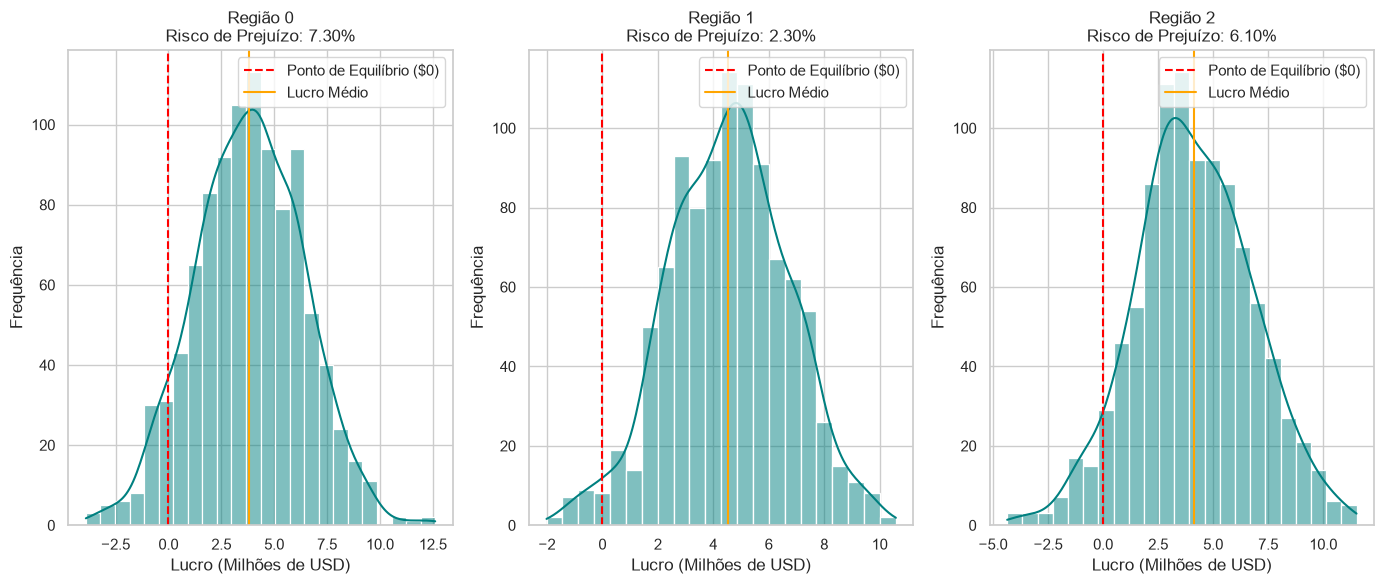

In [9]:
# Gráficos da Distribuição dos Lucros
plt.figure(figsize=(14, 6))

for i, (name, res) in enumerate(bootstrap_results.items(), 1):
    plt.subplot(1, 3, i)
    sns.histplot(res['profits_series'] / 1e6, kde=True, color='teal')
    plt.axvline(0, color='red', linestyle='--', label='Ponto de Equilíbrio ($0)')
    plt.axvline(res['mean_profit'] / 1e6, color='orange', linestyle='-', label='Lucro Médio')
    plt.title(f"{name}\nRisco de Prejuízo: {res['risk_of_loss']:.2f}%")
    plt.xlabel("Lucro (Milhões de USD)")
    plt.ylabel("Frequência")
    plt.legend()

plt.tight_layout()
plt.show()

# 3.8 Conclusão e Recomendação Executiva

### 1. Consolidação dos Resultados Pós-Bootstrap (1.000 Reamostragens)

Após a amostragem de Bootstrap com índices únicos e seleção guiada pelas predições do modelo, foram obtidos os seguintes resultados financeiros e de risco:

Região 0:
- Lucro Médio Líquido: US$ 3.816.285,42
- Intervalo de Confiança (95%): [-US$ 974.513,12 ; US$ 8.785.099,43]
- Risco de Prejuízo: 7,30% (Reprovado — excede o limite de 2,5%)

Região 1 (APROVADA):
- Lucro Médio Líquido: US$ 4.545.975,29
- Intervalo de Confiança (95%): [+US$ 242.137,45 ; US$ 8.701.936,76]
- Risco de Prejuízo: 2,30% (APROVADO — cumpre o critério de ser inferior a 2,5%)

Região 2:
- Lucro Médio Líquido: US$ 4.125.023,03
- Intervalo de Confiança (95%): [-US$ 1.086.948,55 ; US$ 9.436.797,26]
- Risco de Prejuízo: 6,10% (Reprovado — excede o limite de 2,5%)

---

### 2. Análise Crítica dos Resultados
1. Regiões 0 e 2: Falham nos requisitos de governança de risco da OilyGiant. Apresentam risco de prejuízo de 7,30% e 6,10%, respectivamente (muito acima do limite tolerável de 2,5%), além de possuírem limites inferiores negativos no intervalo de confiança.
2. Região 1: É a única região aprovada, pois apresenta um risco de prejuízo de 2,30% (atendendo à regra de ser inferior a 2,5%) e mantém o seu intervalo de confiança de 95% inteiramente no campo positivo (lucro líquido mínimo estatístico de US$ 242.137,45).

---

### 3. Comparação entre a Etapa de Lucro Simples (3.6) e o Bootstrap (3.7)
- A escolha final MUDOU: Na etapa 3.6, ao avaliar apenas o lucro direto dos 200 melhores poços do conjunto de validação, a Região 0 era a escolha sugerida (com ~33,2 milhões de lucro).
- Por que a escolha mudou? A análise simples da etapa 3.6 não considerava a incerteza da amostragem nem a margem de erro do modelo. Quando aplicamos o Bootstrap para simular cenários reais de operação com 500 poços sorteados, o alto erro do modelo na Região 0 (RMSE ~37,6) fez o risco de prejuízo disparar para 7,30%. Por outro lado, a Região 1, devido ao baixíssimo erro do seu modelo (RMSE ~0,89), provou ser muito mais consistente, garantindo um risco de apenas 2,30%. Isso reforça o alto valor de realizar uma análise de risco via Bootstrap antes da tomada de decisão.

---

### 4. Recomendação Final de Investimento
Recomenda-se oficialmente o investimento e desenvolvimento dos 200 poços na REGIÃO 1.

Justificativa Executiva:
Apesar da Região 1 apresentar um volume médio populacional inferior na análise inicial primária, o modelo de Regressão Linear treinado para esta região obteve uma precisão cirúrgica (RMSE de ~0,89). Essa alta acurácia permite ao modelo selecionar os 200 poços realmente mais produtivos dentro da amostragem, assegurando rentabilidade com risco controlado.